# New-to-Credit Consumer Risk Analysis
**Chloe Pham and Grace Ngo · Dickinson College · May 2025**

This notebook reproduces the reviewed analysis on the **original 2,000-profile project CSV fetched from the pinned source**. It connects missing credit-score information, model comparison and threshold selection with an inspectable review trade-off.

The original shared project is [preserved upstream](https://github.com/chloephammi/New-To-Credit-Consumer). This notebook uses the reviewed implementation; it does not replay the original Colab cells or their legacy metrics.

Run `python scripts/fetch_data.py` once, then run the cells in order. There are no credentials or personal paths.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'ntc_risk').is_dir()), None)
if root is None:
    raise RuntimeError('Open this notebook from within the repository checkout.')
sys.path.insert(0, str(root))
from ntc_risk.pipeline import EvaluationConfig, load_csv, run_analysis
from ntc_risk.reporting import profile_data

source = root / 'data/source/v_credit_data_NTC_v51825.csv'
frame = load_csv(source)
profile, schema, coverage = profile_data(frame)
display(pd.Series(profile, dtype=object, name='Value').to_frame())

,Value
n_rows,2000
n_columns,27
positive_outcomes,283
observed_chargeoff_share,0.1415
missing_fico_count,830
missing_fico_share,0.415
duplicate_full_rows,0


## 1. Source coverage and missingness
Keep all 2,000 profiles. The positive label is a recorded charge-off. Missing FICO is preserved as information and handled inside the training pipeline; outcome-associated balance fields are excluded from predictors. See the [data dictionary](../data/data_dictionary.md) for the field policy.

In [2]:
display(schema)
display(coverage.rename(columns={'n':'Profiles','positive':'Recorded charge-offs','observed_share':'Observed share'}))

,column,dtype,missing_count,missing_share,distinct_observed_values
0,No_Hit,int64,0,0.0000,2
1,Age,int64,0,0.0000,8
2,Ever_Bankruptcy,int64,0,0.0000,2
3,Months_Since_Bankruptcy,int64,0,0.0000,23
4,Ever_Collection,int64,0,0.0000,2
5,Unpaid_Collection_Trades,int64,0,0.0000,3
6,Unpaid_Collection_Balance,int64,0,0.0000,64
7,Counseling_Last_12M,int64,0,0.0000,2
8,Unpaid_CO_84M,int64,0,0.0000,2
9,Delinq_90D_12M,int64,0,0.0000,2


,fico_group,Profiles,Recorded charge-offs,Observed share
0,FICO score observed,1170,176,0.150427
1,No FICO score,830,107,0.128916


## 2. Fixed evaluation design
Use a seed of 42 and stratified 70% / 15% / 15% train-validation-test partitions. Select the model by **validation average precision**. For each model, maximize validation precision subject to recall of at least 50% and at least 10 flags across the declared threshold grid. These are illustrative research constraints.

Freeze the selected model and threshold before scoring the test partition. Training-only imputation, a feature allowlist and a no-skill baseline keep the comparisons explicit.

In [3]:
output = root / 'outputs/notebook'
report, comparison = run_analysis(
    frame, output, dataset_kind='coursework', source_path=source,
    config=EvaluationConfig(seed=42),
)
display(pd.DataFrame(report['split_class_counts']).T)
display(comparison[['model','average_precision','roc_auc','threshold','precision','recall','flag_rate']])
print('Frozen model:', report['selected_model'])
print('Frozen threshold:', report['selected_threshold'])

Frozen model: xgboost
Frozen threshold: 0.35


,n,positive,negative
train,1400,198,1202
validation,300,43,257
test,300,42,258


,model,average_precision,roc_auc,threshold,precision,recall,flag_rate
3,xgboost,0.633047,0.920007,0.35,0.506667,0.883721,0.250000
2,random_forest,0.614302,0.932133,0.65,0.578947,0.767442,0.190000
1,logistic_regression,0.508463,0.919283,0.85,0.551724,0.744186,0.193333
0,dummy_prior,0.143333,0.500000,0.05,0.143333,1.000000,1.000000


## 3. Data profile and model comparison
The first chart is descriptive. The second compares models on the validation set; it is not a test-set leaderboard.

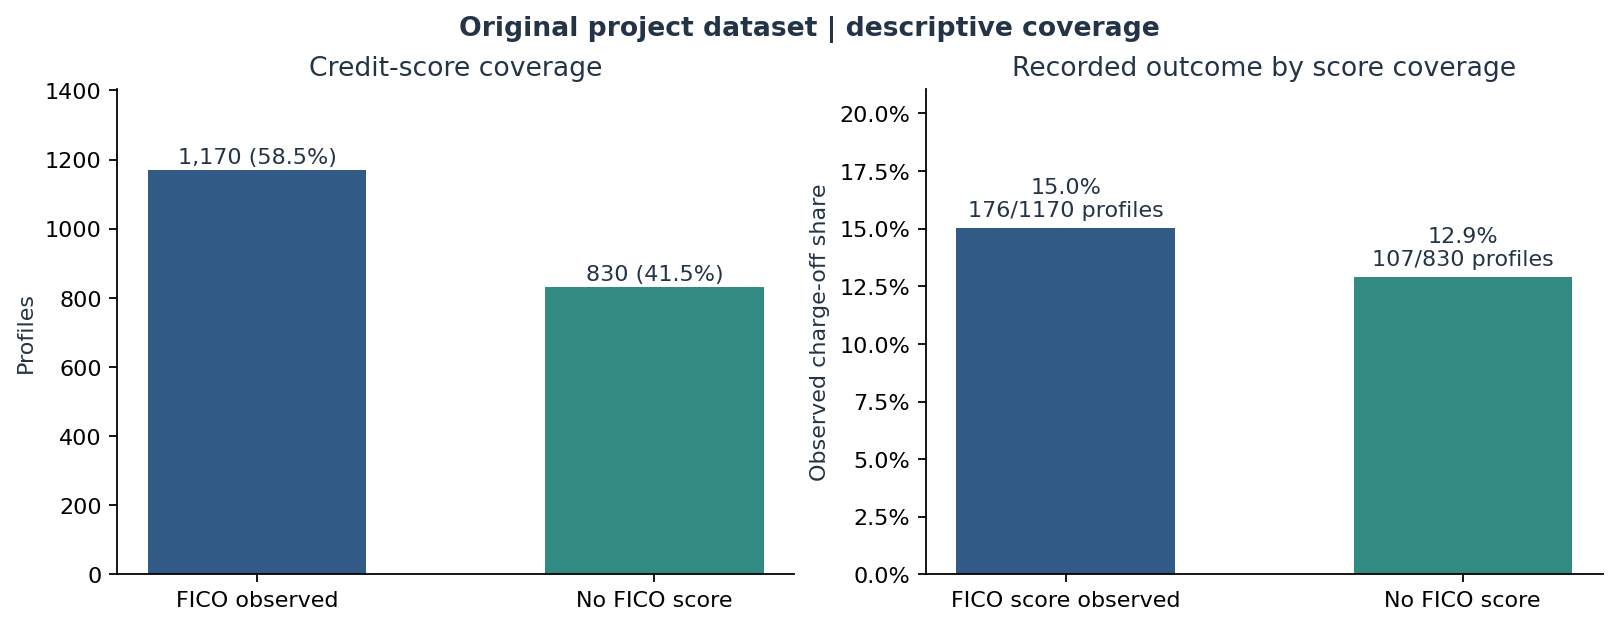

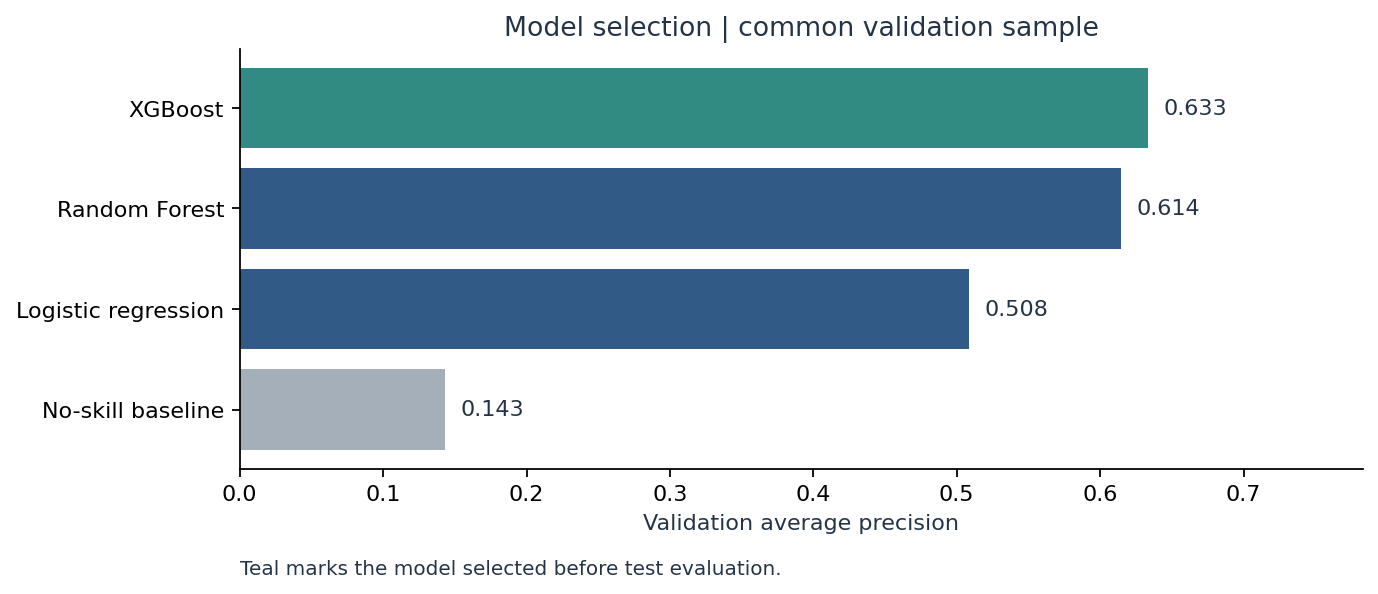

In [4]:
display(Image(filename=str(output / 'figures/data_profile.png')))
display(Image(filename=str(output / 'figures/validation_comparison.png')))

## 4. Threshold trade-offs
A higher score threshold changes which profiles are flagged. Read precision, recall and flagged share together. The vertical line marks the validation-selected threshold, which is also used on the test sample.

,threshold,precision,recall,flag_rate,tp,fp,fn
57,0.05,0.452632,1.000000,0.316667,43,52,0
58,0.10,0.477778,1.000000,0.300000,43,47,0
59,0.15,0.482353,0.953488,0.283333,41,44,2
60,0.20,0.487805,0.930233,0.273333,40,42,3
61,0.25,0.500000,0.930233,0.266667,40,40,3
62,0.30,0.493506,0.883721,0.256667,38,39,5
63,0.35,0.506667,0.883721,0.250000,38,37,5
64,0.40,0.500000,0.837209,0.240000,36,36,7
65,0.45,0.485294,0.767442,0.226667,33,35,10
66,0.50,0.484848,0.744186,0.220000,32,34,11


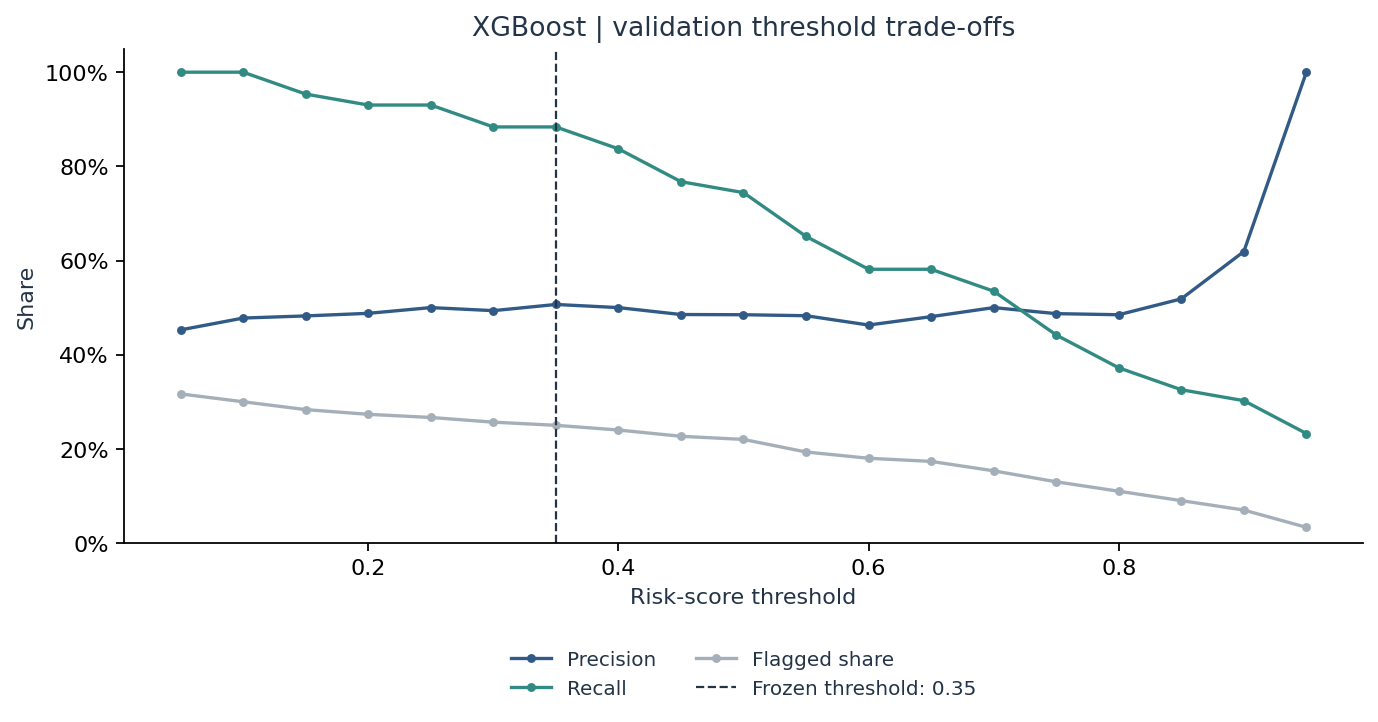

In [5]:
thresholds = pd.read_csv(output / 'validation_thresholds.csv')
display(thresholds[thresholds['model'] == report['selected_model']][['threshold','precision','recall','flag_rate','tp','fp','fn']])
display(Image(filename=str(output / 'figures/validation_thresholds.png')))

## 5. Held-out test evaluation
Only the frozen selected model and the no-skill baseline are evaluated here. ROC AUC measures ranking across false-positive-rate trade-offs; average precision summarizes the precision-recall ranking. Threshold-specific error counts make the review implications concrete.

,model,threshold,n,prevalence,roc_auc,average_precision,brier_score,accuracy,precision,recall,flag_rate,tn,fp,fn,tp
0,xgboost,0.35,300,0.14,0.916851,0.563192,0.101213,0.836667,0.453333,0.809524,0.25,217,41,8,34
1,dummy_prior,0.50,300,0.14,0.500000,0.140000,0.120402,0.860000,0.000000,0.000000,0.00,258,0,42,0


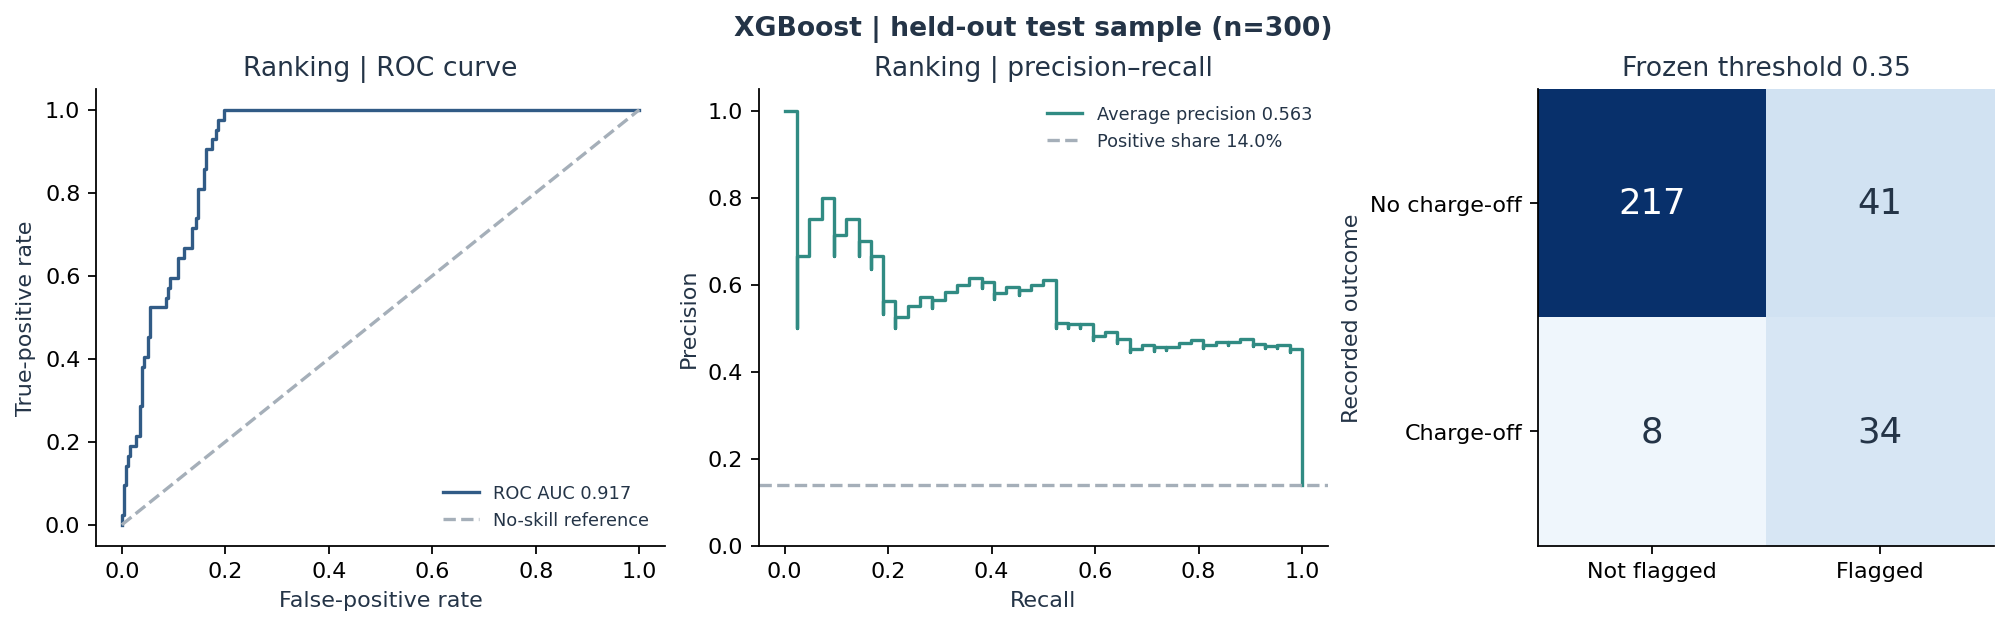

In [6]:
display(pd.read_csv(output / 'test_summary.csv'))
display(Image(filename=str(output / 'figures/test_diagnostics.png')))

## 6. Read the business implication
The reproduced XGBoost run flags 75 of 300 test profiles. It identifies 34 of 42 recorded charge-offs, with 41 false-positive flags and 8 missed positives. Precision is 45.3% and recall is 81.0%. These counts expose the review workload and missed-case trade-off; they are not loan approvals or financial savings.

The study is retrospective. Scores are not calibrated default probabilities, and the source does not define a prospective outcome window. Full technical interpretation is in the [methodological review](../docs/methodology_review.md).

For a fast overview, read the [generated report](../reports/summary.md). For all metrics, source fingerprints, feature exclusions and dependency versions, inspect [`evaluation.json`](../reports/evaluation.json).

In [7]:
display(pd.DataFrame(report['environment'].items(), columns=['Dependency','Version']))
print('Source SHA-256:', report['source_file_sha256'])
print('Data fingerprint:', report['data_fingerprint_sha256'])

Source SHA-256: 8807ab09fdf399d825e92a56633515f86a33f14725c543f6304c32bbbd5ef33b
Data fingerprint: 31bfcf5c5b9cc361614f02d35a2f116548c411d4c7bc91e26b2160c9e953ae6f


,Dependency,Version
0,numpy,2.3.5
1,pandas,2.2.3
2,scikit-learn,1.8.0
3,matplotlib,3.10.8
4,xgboost,3.0.5
